# Text Mining IV: topics, when a text talks about more than one thing
## What are students saying in their course comments?
**Salem Othman · Student notebook**

On Oct 21 you clustered help-desk messages with k-means. It worked, but one problem was left open: a message about wifi **and** printing had to go into **one** cluster.

Today's data has that problem everywhere: **600 practice course comments, generated by code for this exercise** (so everyone gets the same data). They imitate answers to "What should we keep or change in this course?", and many of them talk about two or three things at once.

You'll see k-means struggle, then learn a **topic model**: a method that describes every comment as a **mix** of topics. The last part is a short **review of all of text mining for Exam 2**.

### Today's five steps
| Part | Step | What you do | Exercise |
|---|---|---|---|
| 1 | One label | Cluster the comments with k-means and see what goes wrong | E1 |
| 2 | By hand | Split a tiny table into "comments × topics" and "topics × words" | E2 |
| 3 | Topics | Find the topics in 600 comments and each comment's mix | E3 |
| 4 | How many? | Try 2 to 7 topics and choose | E4 |
| 5 | Review | Exam 2 questions on all of text mining, then audit an AI | E5 |

**For every exercise:** predict → write the code → check → explain.

**How to work**
- Run cells from top to bottom with **Shift + Enter**.
- In an exercise cell, **write the code yourself** under each numbered step. Keep the variable names exactly as written; the Check cell looks for them.
- `PASS` means that step is done. `FIX` tells you what to look at.
- If a Check cell says an exercise **is not finished yet**, that is not an error: write the code in the exercise cell above, run it, then run the Check cell again.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42


def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)


def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print(
            "Write your code in the exercise cell above, run that cell, then run this one again."
        )
        return False
    return True


print("Setup complete.")

Setup complete.


# Part 0 · The comments
| Column | Meaning |
|---|---|
| `comment_id` | Comment number. Never a model input. |
| `comment` | What the student wrote |

**This is practice data**, generated by the code in the next cell. There is **no label column**: nobody has said what each comment is about. That's the point: we want the computer to find the themes.

In [2]:
rng = np.random.default_rng(1030)

# PRACTICE DATA, generated by this code for today's exercise (so everyone gets the same data).
# It imitates end-of-term course comments: "What should we keep or change in this course?"
# Many comments talk about more than one thing.
themes = {
    "exams": (
        [
            "the midterm exam",
            "the final exam",
            "the quizzes",
            "the exam questions",
            "the practice exam",
            "the exam grading",
        ],
        [
            "felt stressful",
            "felt rushed",
            "matched the material",
            "seemed strict",
            "covered too many chapters",
            "needed clearer instructions",
            "seemed fair overall",
        ],
    ),
    "labs": (
        [
            "the labs",
            "the lab software",
            "the lab computers",
            "the lab sessions",
            "my lab partner",
            "the lab assignments",
        ],
        [
            "made the coding fun",
            "kept crashing",
            "felt hands-on and useful",
            "ran very slowly",
            "needed better setup",
            "confused me at first",
            "taught me the most",
        ],
    ),
    "workload": (
        [
            "the homework",
            "the weekly homework",
            "the reading",
            "the project deadlines",
            "the workload",
            "the homework load",
        ],
        [
            "took hours every week",
            "piled up fast",
            "seemed manageable",
            "overlapped with other courses",
            "felt like too much",
            "left no free weekends",
            "kept me busy all semester",
        ],
    ),
    "lectures": (
        [
            "the lectures",
            "the lecture slides",
            "the professor",
            "the lecture examples",
            "the class discussions",
            "the recorded lectures",
        ],
        [
            "explained things clearly",
            "moved too quickly",
            "kept us engaged",
            "lost me sometimes",
            "helped me understand",
            "could use more examples",
            "stayed well organized",
        ],
    ),
}
openers = ["", "", "", "Honestly, ", "In my opinion, ", "This term, "]
joins = [" and ", ". Also, ", ", but ", ". On the other hand, "]


def phrase(topic):
    subjects, verbs = themes[topic]
    return f"{subjects[rng.integers(len(subjects))]} {verbs[rng.integers(len(verbs))]}"


def comment(topics):
    text = rng.choice(openers) + phrase(topics[0])
    for t in topics[1:]:
        text += rng.choice(joins) + phrase(t)
    text = text + "."
    return text[0].upper() + text[1:]


rows = []
for _ in range(600):
    k = rng.choice(
        [1, 2, 3], p=[0.45, 0.42, 0.13]
    )  # how many things the student talks about
    topics = list(rng.choice(list(themes), size=k, replace=False))
    rows.append(comment(topics))

comments = pd.DataFrame({"comment": rows})
comments.insert(0, "comment_id", [f"C{i:03d}" for i in range(1, len(comments) + 1)])

print("Comments:", len(comments))
display(comments.head(10))

Comments: 600


,comment_id,comment
0,C001,The homework load left no free weekends.
1,C002,"In my opinion, the lectures kept us engaged. On the other hand, the homework piled up fast."
2,C003,"Honestly, the exam questions seemed fair overall."
3,C004,"This term, the weekly homework took hours every week."
4,C005,The professor moved too quickly.
5,C006,"Honestly, the lab sessions ran very slowly. Also, the workload piled up fast."
6,C007,"The practice exam needed clearer instructions. On the other hand, the lab software confused me at first."
7,C008,"The lab software needed better setup. On the other hand, the practice exam seemed strict."
8,C009,"In my opinion, the weekly homework piled up fast. On the other hand, the professor helped me understand."
9,C010,The project deadlines took hours every week.


**Write:** read the 10 comments above. How many of them talk about more than one thing? Which things?

*Your answer:*
There were 5 comments with multiple topics. The topics were homework, practice exams, and labs. 

# Part 1 · k-means gives each comment one label
You know this from Oct 21: turn every comment into TF-IDF numbers, then let k-means find groups. Each cluster is read by the biggest words in its centre.

There seem to be four themes, so try k = 4.

### E1 · Cluster the comments
**Predict:** will each of the 4 clusters be about one clear theme?
No, they won't have a clear theme. 

In [3]:
vectorizer = None
tfidf = None
kmeans = None
cluster_words = None

examples = [1, 5, 6, 7]  # rows of four comments that each talk about two things

# Write your code below. Your code must create the variables set to None above.

# 1. vectorizer: TfidfVectorizer(stop_words="english").
#    tfidf: the TF-IDF matrix of comments["comment"].
vectorizer = TfidfVectorizer(stop_words="english")

tfidf = vectorizer.fit_transform(comments["comment"])

# 2. kmeans: KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE) fitted on tfidf.
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(tfidf)
# 3. cluster_words: a dictionary {cluster number: list of its 6 biggest words}. Print it.
#    Hint: terms = vectorizer.get_feature_names_out()
#    Hint: list(terms[np.argsort(kmeans.cluster_centers_[j])[::-1][:6]])
terms = vectorizer.get_feature_names_out()
cluster_words = {
    j: list(terms[np.argsort(kmeans.cluster_centers_[j])[::-1][:6]])
    for j in range(kmeans.n_clusters)
}
display(cluster_words)
# 4. Show the comments in `examples` with the cluster each one was put in.
#    Hint: comments.loc[examples].assign(cluster=kmeans.labels_[examples])
display(comments.loc[examples].assign(cluster=kmeans.labels_[examples]))

{0: ['needed', 'better', 'setup', 'week', 'took', 'hours'],
 1: ['lab', 'slowly', 'ran', 'partner', 'moved', 'quickly'],
 2: ['exam', 'felt', 'practice', 'grading', 'fair', 'overall'],
 3: ['homework', 'lecture', 'examples', 'weekends', 'left', 'free']}

,comment_id,comment,cluster
1,C002,"In my opinion, the lectures kept us engaged. On the other hand, the homework piled up fast.",3
5,C006,"Honestly, the lab sessions ran very slowly. Also, the workload piled up fast.",1
6,C007,"The practice exam needed clearer instructions. On the other hand, the lab software confused me at first.",0
7,C008,"The lab software needed better setup. On the other hand, the practice exam seemed strict.",0


**Check E1**

In [4]:
if ready(tfidf, "E1") and ready(kmeans, "E1") and ready(cluster_words, "E1"):
    check("one TF-IDF row per comment", tfidf.shape[0] == len(comments))
    check(
        "k-means made 4 clusters",
        kmeans.n_clusters == 4 and len(set(kmeans.labels_)) == 4,
    )
    check(
        "cluster_words has 6 words for each cluster",
        len(cluster_words) == 4 and all(len(w) == 6 for w in cluster_words.values()),
    )
    _terms = vectorizer.get_feature_names_out()
    check(
        "each cluster's words are the 6 biggest in its k-means centre",
        all(
            set(cluster_words[j])
            == set(_terms[np.argsort(kmeans.cluster_centers_[j])[::-1][:6]])
            for j in range(4)
        ),
    )

PASS  one TF-IDF row per comment
PASS  k-means made 4 clusters
PASS  cluster_words has 6 words for each cluster
PASS  each cluster's words are the 6 biggest in its k-means centre


**Write:** can you name each cluster with one theme? Look at the four example comments: what did k-means have to do with each of them?

*Your answer:*
The clusters with one theme are: clusters 1, 2, and 3. k-means didn't choose them as frequently as cluster 0 because cluster 0 covered a broader range. 

# Part 2 · A topic model, by hand
A **topic model** describes the data differently:
- a **topic** is a list of words with weights (the "exam" topic: *exam* heavy, *stressful* heavy, *lab* zero...)
- every comment is a **mix** of topics (C007: half exams, half labs)

The method we use is **NMF**, non-negative matrix factorization. It splits the count table into two smaller tables:

**count table (comments × words) ≈ mix table (comments × topics) × topic table (topics × words)**

- *Non-negative*: every number is 0 or more. A comment can't be "minus 1 exam".
- The computer finds both small tables by **guessing, then adjusting them round after round**, so that multiplying them back gives a table as close as possible to the real counts. The leftover difference is the **reconstruction error**.

The slides do it by hand, one step per slide, on the 4 tiny comments below.

In [5]:
tiny_counts = pd.DataFrame(
    [[1, 1, 1, 0, 0, 0], [0, 0, 0, 1, 1, 1], [1, 1, 1, 1, 1, 1], [0, 0, 0, 2, 2, 2]],
    columns=["exam", "stressful", "rushed", "lab", "crashed", "slow"],
    index=["C1", "C2", "C3", "C4"],
)
display(tiny_counts)

,exam,stressful,rushed,lab,crashed,slow
C1,1,1,1,0,0,0
C2,0,0,0,1,1,1
C3,1,1,1,1,1,1
C4,0,0,0,2,2,2


### E2 · NMF on the tiny table
**Predict:** with 2 topics, what will the two topics be? What mix will C3 get?

In [6]:
tiny_model = None
tiny_mix = None
tiny_topics = None
rebuilt = None

# Write your code below. Your code must create the variables set to None above.

# 1. tiny_model: NMF(n_components=2, init="nndsvda", random_state=RANDOM_STATE, max_iter=2000).
#    Fit it AND get the mix table in one step:
#    Hint: mix = tiny_model.fit_transform(tiny_counts.to_numpy())
tiny_model = NMF(
    n_components=2, init="nndsvda", random_state=RANDOM_STATE, max_iter=2000
)

# 2. tiny_mix: the mix table as a DataFrame (rows C1..C4, columns "topic 0", "topic 1").
#    tiny_topics: tiny_model.components_ as a DataFrame (rows "topic 0", "topic 1", columns = the words).
#    Display both, rounded to 2 decimals.
tiny_mix = pd.DataFrame(
    tiny_model.fit_transform(tiny_counts.to_numpy()),
    index=tiny_counts.index,
    columns=["topic 0", "topic 1"],
)

tiny_topics = pd.DataFrame(
    tiny_model.components_, index=["topic 0", "topic 1"], columns=tiny_counts.columns
)

# 3. rebuilt: multiply them back: tiny_mix.to_numpy() @ tiny_topics.to_numpy(),
#    as a DataFrame shaped like tiny_counts. Display it rounded to 2 decimals.
#    Print the reconstruction error: tiny_model.reconstruction_err_
rebuilt = pd.DataFrame(
    tiny_mix.to_numpy() @ tiny_topics.to_numpy(),
    index=tiny_counts.index,
    columns=tiny_counts.columns,
)

display(tiny_mix.round(2))
display(tiny_topics.round(2))
display(rebuilt.round(2))
print("Reconstruction error:", tiny_model.reconstruction_err_)

,topic 0,topic 1
C1,0.00,0.89
C2,0.55,0.00
C3,0.55,0.89
C4,1.10,0.00


,exam,stressful,rushed,lab,crashed,slow
topic 0,0.00,0.00,0.00,1.83,1.83,1.83
topic 1,1.13,1.13,1.13,0.00,0.00,0.00


,exam,stressful,rushed,lab,crashed,slow
C1,1.0,1.0,1.0,0.0,0.0,0.0
C2,0.0,0.0,0.0,1.0,1.0,1.0
C3,1.0,1.0,1.0,1.0,1.0,1.0
C4,0.0,0.0,0.0,2.0,2.0,2.0


Reconstruction error: 0.0002916029366629378


**Check E2**

In [7]:
if (
    ready(tiny_model, "E2")
    and ready(tiny_mix, "E2")
    and ready(tiny_topics, "E2")
    and ready(rebuilt, "E2")
):
    check("tiny_mix is 4 comments x 2 topics", tiny_mix.shape == (4, 2))
    check("tiny_topics is 2 topics x 6 words", tiny_topics.shape == (2, 6))
    check(
        "no negative numbers anywhere",
        (tiny_mix.to_numpy() >= 0).all() and (tiny_topics.to_numpy() >= 0).all(),
    )
    check(
        "rebuilt = mix x topics",
        np.allclose(rebuilt.to_numpy(), tiny_mix.to_numpy() @ tiny_topics.to_numpy()),
    )
    check(
        "multiplying back gives the counts again",
        np.allclose(rebuilt.to_numpy(), tiny_counts.to_numpy(), atol=0.05),
    )

PASS  tiny_mix is 4 comments x 2 topics
PASS  tiny_topics is 2 topics x 6 words
PASS  no negative numbers anywhere
PASS  rebuilt = mix x topics
PASS  multiplying back gives the counts again


**Write:** (a) Which words does each topic contain? What mix did C3 get? (b) The numbers are not the 1s and 0s from the slides. Why does that not matter?

*Your answer:*
Topic 0 contains lab, crashed, and slow. 
Topic 1 contains exam, stressful, and rushed. 
C3 got both topic 0 and 1. 

# Part 3 · Topics in 600 comments
Same method on the TF-IDF table from E1. Two tables come out:
- `components_` (topics × words): read each topic by its biggest words, as you read k-means clusters.
- the **mix** from `fit_transform` (comments × topics): how much of each topic each comment contains.

The mix numbers have no fixed scale (E2): one topic row could be made twice as big and its mix column half as big, and mix × topics would not change. So put every topic on the **same scale** before comparing:
1. **Size of each topic:** the total of its row in `components_`.
2. **Scaled mix:** multiply each topic's mix column by that size. (This is the mix you'd get if every topic row added up to 1; mix × topics is unchanged.)
3. **Shares:** divide each comment's scaled mix by its row total, so the shares add up to 1.

Read a share as the model's **estimate of how much a topic contributes** to the comment, not an exact percentage of its words.

### E3 · Find the topics, and each comment's mix
**Predict:** what will the four example comments' shares look like?

In [8]:
topic_model = None
topic_words = None
shares = None

k_topics = 4

# Write your code below. Your code must create the variables set to None above.

# 1. topic_model: NMF(n_components=k_topics, init="nndsvda", random_state=RANDOM_STATE, max_iter=1000).
#    mix = topic_model.fit_transform(tfidf)
topic_model = NMF(
    n_components=k_topics, init="nndsvda", random_state=RANDOM_STATE, max_iter=1000
)
mix = topic_model.fit_transform(tfidf)

# 2. topic_words: a dictionary {topic number: list of its 6 biggest words}. Print it.
#    Hint: list(terms[np.argsort(topic_model.components_[t])[::-1][:6]])

terms = vectorizer.get_feature_names_out()
topic_words = {
    t: list(terms[np.argsort(topic_model.components_[t])[::-1][:6]])
    for t in range(k_topics)
}

# 3. Put the topics on one scale, then make shares.
#    Hint: topic_size = topic_model.components_.sum(axis=1)      # one number per topic
#    Hint: scaled_mix = mix * topic_size                          # mix x topics is unchanged
#    shares: each row of scaled_mix divided by its row total, as a DataFrame
#    (one row per comment, columns "topic 0" ... "topic 3").
#    Hint: scaled_mix / scaled_mix.sum(axis=1, keepdims=True)
#    Display the shares of the comments in `examples`, rounded to 2 decimals, with the comment text.
topic_size = topic_model.components_.sum(axis=1)
scaled_mix = mix * topic_size
shares = pd.DataFrame(
    scaled_mix / scaled_mix.sum(axis=1, keepdims=True),
    index=comments.index,
    columns=[f"topic {t}" for t in range(k_topics)],
)
# 4. Print how many comments have at least 2 topics with a share of 0.2 or more.
#    Hint: ((shares >= 0.2).sum(axis=1) >= 2).sum()
print(
    "Number of comments with at least 2 topics having a share of 0.2 or more:",
    ((shares >= 0.2).sum(axis=1) >= 2).sum(),
)

Number of comments with at least 2 topics having a share of 0.2 or more: 340


**Check E3**

In [9]:
if ready(topic_model, "E3") and ready(topic_words, "E3") and ready(shares, "E3"):
    check(
        "the topic model has k_topics topics",
        topic_model.components_.shape[0] == k_topics,
    )
    check(
        "topic_words has 6 words per topic",
        len(topic_words) == k_topics and all(len(w) == 6 for w in topic_words.values()),
    )
    check(
        "shares has one row per comment and one column per topic",
        shares.shape == (len(comments), k_topics),
    )
    check("every comment's shares add up to 1", np.allclose(shares.sum(axis=1), 1))
    check("no share is negative", (shares.to_numpy() >= 0).all())
    _terms = vectorizer.get_feature_names_out()
    check(
        "each topic's words are the 6 biggest in its components_ row",
        all(
            set(topic_words[t])
            == set(_terms[np.argsort(topic_model.components_[t])[::-1][:6]])
            for t in range(k_topics)
        ),
    )
    _scaled = topic_model.transform(tfidf) * topic_model.components_.sum(axis=1)
    _expected = _scaled / _scaled.sum(axis=1, keepdims=True)
    check(
        "the shares match the fitted model (topics put on one scale first)",
        np.allclose(shares.to_numpy(), _expected, atol=0.01),
    )

PASS  the topic model has k_topics topics
PASS  topic_words has 6 words per topic
PASS  shares has one row per comment and one column per topic
PASS  every comment's shares add up to 1
PASS  no share is negative
PASS  each topic's words are the 6 biggest in its components_ row
PASS  the shares match the fitted model (topics put on one scale first)


### Worked example · Topic shares of the four example comments

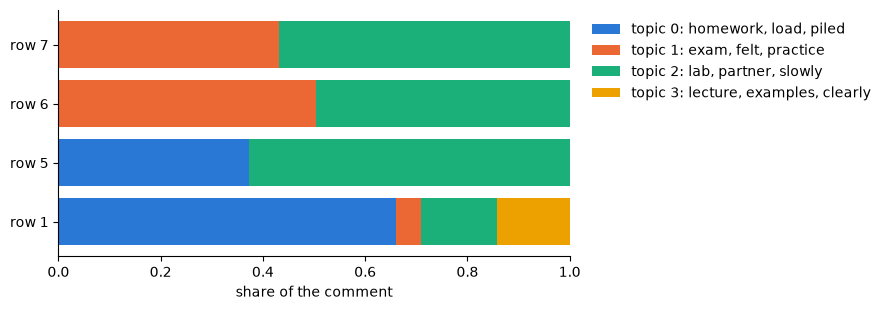

In [10]:
if ready(shares, "E3"):
    colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    left = np.zeros(len(examples))
    for t in range(k_topics):
        values = shares.loc[examples, f"topic {t}"].to_numpy()
        ax.barh(
            [f"row {i}" for i in examples],
            values,
            left=left,
            color=colours[t % 4],
            label=f"topic {t}: {', '.join(topic_words[t][:3])}",
        )
        left += values
    ax.set_xlabel("share of the comment")
    ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Write:** name each topic. Then compare with E1: what does the topic model say about the four example comments that k-means could not?

*Your answer:*

**Topic names:**
- Topic 0: Workload
- Topic 1: Exams
- Topic 2: Labs
- Topic 3: Lectures

- **k-means:** Forced each comment into a single cluster, missing the fact that these comments talk about multiple things at once.
- **Topic model:** Quantifies each comment as a mix of multiple topics with explicit shares (for example, showing that row 6 is split between Topic 1 (Exams) and Topic 2 (Labs), and row 5 is a mix of Workload and Labs).

# Part 4 · How many topics?
Like k in k-means, you choose the number of topics. The **reconstruction error** is how far mix × topics is from the real table. Adding a topic gives the model more freedom, so the **best possible** error can't go up (the extra topic could just be all zeros). In practice the error almost always falls as k grows, like inertia. (Each k is a separate fit that can stop at a slightly different solution, so a tiny bump is possible.) Either way, the lowest error is not the answer.

The deciding question is the same one as for clusters: **can you name each topic, and are the topics different from each other?**

### E4 · Try 2 to 7 topics
**Predict:** what will happen to the error as you add topics?

In [11]:
error_table = None
topics_by_k = None
chosen_k = None

k_values = range(2, 8)

# Write your code below. Your code must create the variables set to None above.

# 1. For every k in k_values, fit NMF(n_components=k, init="nndsvda", random_state=RANDOM_STATE, max_iter=1000)
#    on tfidf. Collect k and the reconstruction error in error_table (a DataFrame). Display it.
#    Hint: model.reconstruction_err_
for k in k_values:
    model = NMF(
        n_components=k, init="nndsvda", random_state=RANDOM_STATE, max_iter=1000
    )
    model.fit(tfidf)
    if error_table is None:
        error_table = pd.DataFrame(columns=["k", "reconstruction error"])
    error_table = pd.concat(
        [
            error_table,
            pd.DataFrame({"k": [k], "reconstruction error": [model.reconstruction_err_]}),
        ],
        ignore_index=True,
    )



# 2. topics_by_k: a dictionary {k: list of topics, each a list of its 5 biggest words}.
#    Print the topics for k = 3, 4 and 5.
topics_by_k = {}

for k in k_values:
    model = NMF(
        n_components=k, init="nndsvda", random_state=RANDOM_STATE, max_iter=1000
    )
    model.fit(tfidf)
    topics_by_k[k] = []
    feature_names = vectorizer.get_feature_names_out()
    for i, topic in enumerate(model.components_):
        top_words = [feature_names[j] for j in topic.argsort()[::-1][:5]]
        topics_by_k[k].append(top_words)

print("Error Table:")
display(error_table)
print("Topics by k:")
for k in [3, 4, 5]:
    print(f"Topics for k={k}:")
    for i, topic in enumerate(topics_by_k[k]):
        print(f"  Topic {i}: {', '.join(topic)}")

# 3. chosen_k: the number of topics you would use. Explain your choice in the answer cell.
chosen_k = 4 


Error Table:


,k,reconstruction error
0,2,22.763105
1,3,22.236626
2,4,21.760515
3,5,21.328347
4,6,20.912911
5,7,20.517289


Topics by k:
Topics for k=3:
  Topic 0: homework, lecture, examples, clearly, things
  Topic 1: exam, felt, practice, grading, overall
  Topic 2: lab, partner, slowly, ran, computers
Topics for k=4:
  Topic 0: homework, load, piled, fast, project
  Topic 1: exam, felt, practice, grading, overall
  Topic 2: lab, partner, slowly, ran, computers
  Topic 3: lecture, examples, clearly, things, explained
Topics for k=5:
  Topic 0: homework, load, piled, fast, week
  Topic 1: exam, felt, practice, overall, fair
  Topic 2: lab, ran, slowly, partner, computers
  Topic 3: lecture, examples, things, explained, clearly
  Topic 4: needed, better, setup, clearer, instructions


**Check E4**

In [12]:
if ready(error_table, "E4") and ready(topics_by_k, "E4") and ready(chosen_k, "E4"):
    check("error_table has one row per k", len(error_table) == len(k_values))
    check(
        "the error at the largest k is lower than at the smallest k",
        error_table["reconstruction error"].iloc[-1]
        < error_table["reconstruction error"].iloc[0],
    )
    check(
        "topics_by_k has k topics for each k",
        all(len(topics_by_k[k]) == k for k in k_values),
    )
    check("chosen_k is one of the values you tried", chosen_k in k_values)

PASS  error_table has one row per k
PASS  the error at the largest k is lower than at the smallest k
PASS  topics_by_k has k topics for each k
PASS  chosen_k is one of the values you tried


### Worked example · The error curve

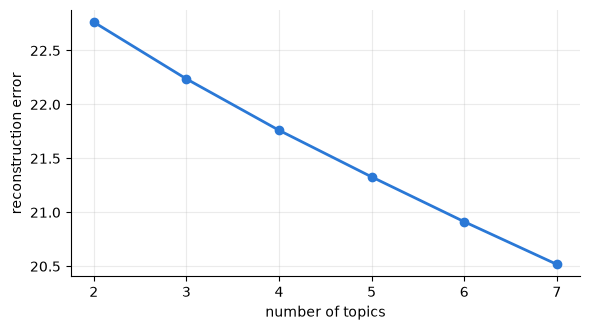

In [13]:
if ready(error_table, "E4"):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot(
        error_table["k"],
        error_table["reconstruction error"],
        color="#2a78d6",
        marker="o",
        linewidth=2,
    )
    ax.set_xlabel("number of topics")
    ax.set_ylabel("reconstruction error")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Write:** read the topics for k = 3, 4 and 5. Which k would you choose, and why? Why can't the error curve decide for you?

*Your answer:*
I would chose k = 4. The error curve cant decide because it generally decreases as the model adds topics. 

# Part 5 · Text mining review for Exam 2
Exam 2 is on **Wednesday, November 18**, and covers frequent itemsets, clustering, text mining and graph mining. Answer these without running code: they cover the four text-mining classes (Oct 21, 23, 28 and today).

1. A bag of words throws away word order. Give an example of two sentences with different meanings that get exactly the same word counts, and one fix.
2. TF-IDF: why does a word that appears in almost every message get a small weight?
3. When you train a text classifier, why must the vectorizer be fitted on the training texts only?
4. Naive Bayes: why do we add one to every word count?
5. For sentiment, why must stop-word removal be done carefully?
6. k-means and a topic model both find groups in text. What can a topic model say about a text that k-means cannot?

*Your answers:*
1.
2.
3.
4.
5.
6.

### E5 · The AI's analysis
The department asks an AI assistant to summarise the 600 comments. It replies:

> "The topic model read the comments and understood them: it knows topic 2 is about labs because it knows what a lab is. I used 7 topics, because 7 has the lowest reconstruction error, so it fits best. To report how many comments are about each topic, I counted each comment's biggest topic only."

Each claim can be checked against your notebook.

**Write:** find **three** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. The topic model does not know what a lab is, it is purely statistical and does not understand what each word means. 
2. The more topics that are added makes each topic less coherent and introduces noise. 
3. Taking each topics biggest topic is against the point to use a topic model. KMeans misses out on secondary topics in each comment. 

**Ask your AI (optional, 5 minutes).** Copy the five topic lists for k = 5 from E4 into your own AI tool and ask: *"Is 5 the right number of topics for these course comments?"* Then grade its reply: does it say what the extra topic means, does it rely on the error alone, does it ask what the analysis is for?

*The AI's answer, in one or two sentences:*

*Your grade of it, and why:*

### Challenge tasks (optional)
1. Pick a share threshold (0.2) and count how many comments mention each topic. How different is it from counting only the biggest topic?
2. Run `NMF` with `init="random"` and `random_state` 0, 1 and 2. Do the topics change? Why do we always fix `random_state` (and use the same library versions) when everyone must get the same answer?
3. Find the comment with the most even mix (the smallest biggest share). What does it say?

# Exit ticket
Answer without running more code.
1. In one sentence each: what is a topic, and what is a comment's mix?
2. Why does the reconstruction error usually fall as you add topics? What does it remind you of?
3. Who named the topics today: the computer or you? Why does that matter?

*Your answers:*
1. A topic is a cluster formed by the words in the comment. A mixed comment has two or more clusters. 
2. Reconstruction error falls because the model has more freedom to create topics. 
3. I named the topics. The computer does not understand the semantic meaning of each word. So it cannot give a name to any topic, this job is reserved for humans. 

# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* cell is filled in.
- Submit this notebook with its outputs.

**Next week:** no class meetings on Wednesday Nov 4 or Friday Nov 6: two self-study classes on graph mining. Your **project proposal is due Friday November 6, 11:59 PM**.